# 04 — Training SATA (P5, 5a)

**Status (11 October 2026):** done. Gate S3a and the first epochs ran on the Mac, the rest of training and the LLM runs (stage F) on a Runpod H200. The RQ4 test is in notebook 05, section 11.

**What SATA is, in plain English.** SATA is a small transformer. It reads a task's whole pool of 256 labelled rows together with one query, and gives every row a score for how useful it would be as a demonstration for that query. The 8 demonstrations are its top 4 rows of each label.

It is trained only on synthetic tasks, where the generator knows the truth about every row, so it can be told which rows are good (its *targets*). Two versions of the targets are compared (`hiccups/21`):
- **Planned (structural) targets**, as first designed: +2 for a row in the query's regime (the same sign pattern of the three rule features), +1.5 for a row whose shortcut disagrees with its label, −1.5 for a row whose shortcut agrees and sits outside the query's regime. In P5, label-noise rows lost their bonus. These targets turned out to teach the shortcut *backwards*, so they are kept only as the `sata_designed` ablation.
- **Matched targets**, used by SATA-v2 (the user's decision, 10 October). A row's target is its chance of being in a *matched set*: within each label, 2 clean rows whose shortcut disagrees with the label, each paired with the clean agreeing row nearest in shortcut size, the query's regime first. Half the set agrees with the shortcut, so the shortcut tells the reader nothing about the label. This mirrors the counter_spurious strategy, with the regime preference added.

SATA never sees these tags when it selects. It has to infer them from the rows' features and labels, so what it learns must carry over from the training tasks to new ones.

**What this notebook does.**
1. **Gate S3a:** do the targets themselves, applied directly with no model, beat the hand-designed strategies? If not, nothing trained on them can.
2. **Device:** CPU against Apple Metal for SATA's small batches.
3. **Training curves** for SATA-v2, its query-agnostic ablation (a blank query), and the planned-target ablation.
4. **The trained models on the proxy,** against the targets and the strategies.
5. **The LLM validation** on 8 held-out tasks (pending stage F).

**The proxy.** An XGBoost classifier is fitted on just the 8 chosen rows and predicts the query. A set that teaches the rule lets it predict well in every environment, while a set that teaches the shortcut fails under spurious reversal. SATA's early stopping uses the worst of ID, covariate and spurious reversal. The mechanism placebo is trained on and reported, but not used to choose.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
from src.utils.config import load_config, resolve_path  # first src import: sets the thread and MPS settings

config = load_config()

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.evaluation import plots
from src.models.sata import load_sata
from src.models.sata_gate import STRATEGIES, proxy_compare, summarise
from src.models.sata_train import sample_sata_tasks, sata_config

plots.use_style()
RESULTS = resolve_path(config.paths.results)
P5 = RESULTS / "p5"
cfg = sata_config(config)
EVAL_ENVS = tuple(cfg.selection_environments)
ENV_COLOURS = dict(zip(EVAL_ENVS, plots.SERIES))
NAMES = {"oracle_matched": "matched targets (no model)", "oracle_target": "planned targets (no model)",
         "oracle_target_designed": "planned targets as first designed",
         "sata": "SATA-v2", "sata_agnostic": "SATA-v2, blank query", "sata_designed": "SATA, planned targets"}
VARIANTS = ("sata", "sata_agnostic", "sata_designed")
def name(m):
    if m.endswith(" (top-k)"):
        return NAMES.get(m[: -len(" (top-k)")], m) + " (top 4)"
    return NAMES.get(m, m)

## 1. Gate S3a: are the targets worth learning?

Run by `scripts/gate_s3a_oracle_check.py` on SATA's 100 validation tasks. These come from the same distribution as the evaluation tasks but share none of their seeds. Each task gives 32 queries per environment. Every method picks 8 demonstrations per query from an ID pool; the mechanism placebo uses a matched pool.

- **"Matched targets (no model)"** takes the top 4 rows of each label by SATA-v2's target scores.
- **"Planned targets (no model)"** does the same with the planned targets (label-noise fix applied).
- **"Planned targets as first designed"** shows them before the fix.
- **The strategies** are the grid's own (`protocols.select`). counter_prior is left out, because it needs Qwen's measured prior.

**Pass:** the targets' worst evaluated environment is at least the best strategy's.

Gate S3a on 100 tasks: targets 0.640 against the best strategy (counter_spurious) 0.555 -> PASS


,id,covariate,spurious_reversal,mechanism,worst,shortcut_agrees,label_noise,same_regime
method,,,,,,,,
matched targets (no model),0.655,0.671,0.640,0.681,0.640,0.598,0.000,0.676
planned targets (no model),0.556,0.585,0.671,0.589,0.556,0.251,0.000,0.720
counter_spurious,0.581,0.555,0.595,0.609,0.555,0.500,0.000,0.126
feature_range,0.578,0.575,0.507,0.596,0.507,0.657,0.072,0.125
planned targets as first designed,0.476,0.522,0.657,0.501,0.476,0.236,0.090,0.766
random,0.550,0.533,0.468,0.547,0.468,0.838,0.019,0.124
similarity,0.684,0.680,0.462,0.688,0.462,0.759,0.036,0.329
label_diversity,0.661,0.651,0.431,0.675,0.431,0.836,0.020,0.125
rule_diversity,0.680,0.684,0.368,0.689,0.368,0.849,0.000,0.125


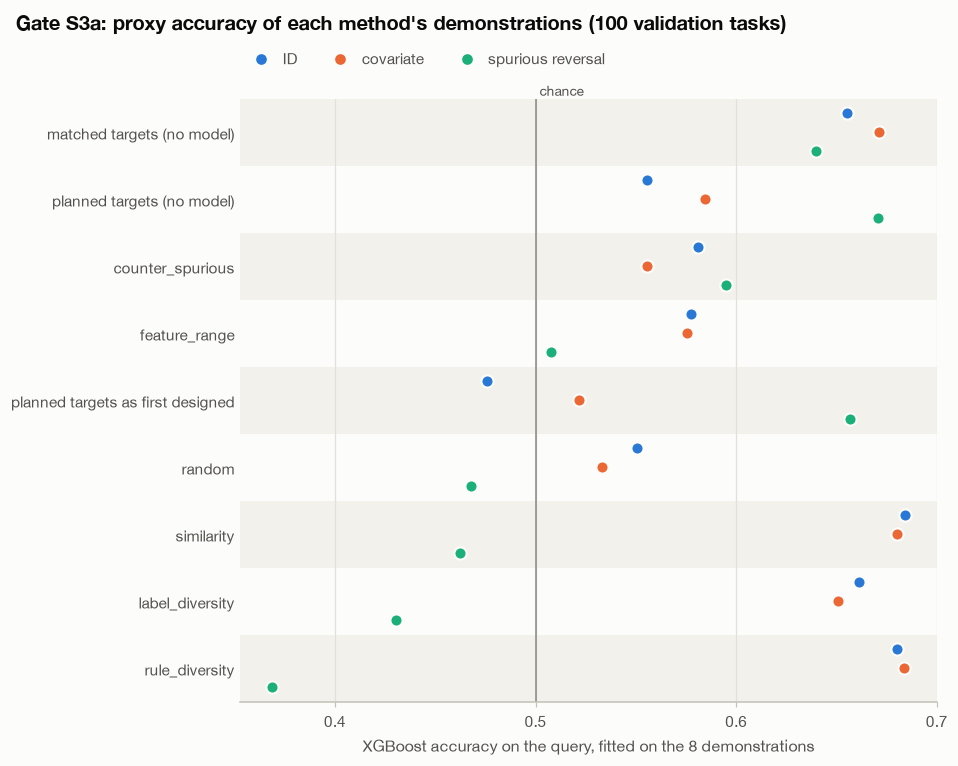

In [2]:
gate = json.loads((P5 / "gate_s3a.json").read_text())
per_task = pd.read_parquet(P5 / "gate_s3a.parquet")
table = summarise(per_task, EVAL_ENVS)
print(f"Gate S3a on {gate['n_tasks']} tasks: targets {gate['oracle_worst']:.3f} against the best strategy "
      f"({gate['best_strategy']}) {gate['best_strategy_worst']:.3f} -> {'PASS' if gate['passed'] else 'FAIL'}")
show = table[[*EVAL_ENVS, "mechanism", "worst", "shortcut_agrees", "label_noise", "same_regime"]].rename(index=name)
display(show.round(3))

order = list(table.index)
long = per_task[per_task.env.isin(EVAL_ENVS)].groupby(["method", "env"])["accuracy"].mean().reset_index()
long["method"] = long["method"].map(name)
fig, (ax,) = plots.panels(title="Gate S3a: proxy accuracy of each method's demonstrations (100 validation tasks)",
                          size=(8.6, plots.dots_height(len(order), 3) + 0.7))
plots.dots(ax, long, y="method", x="accuracy", hue="env", y_order=[name(m) for m in order], hue_order=list(EVAL_ENVS),
           colours=plots.SERIES, xlabel="XGBoost accuracy on the query, fitted on the 8 demonstrations")
plots.reference(ax, 0.5, "chance")
plots.key(fig, [plots.label(e) for e in EVAL_ENVS], plots.SERIES)
plt.show()

**Reading the chart.**
- **The matched targets (top row) are the only method with no weak environment:** 0.655, 0.671 and 0.640. The best hand-designed strategy's worst is 0.555 (counter_spurious), so gate S3a passes.
- **The planned targets** score 0.671 under reversal but only 0.556 on ID, because they show the shortcut reversed. **As first designed** they also picked label-noise rows and failed (0.476).
- **label_diversity, similarity and rule_diversity** are strong on ID and covariate (0.65–0.68) but collapse under spurious reversal (0.37–0.46): their sets show the shortcut agreeing with the label about 80% of the time.

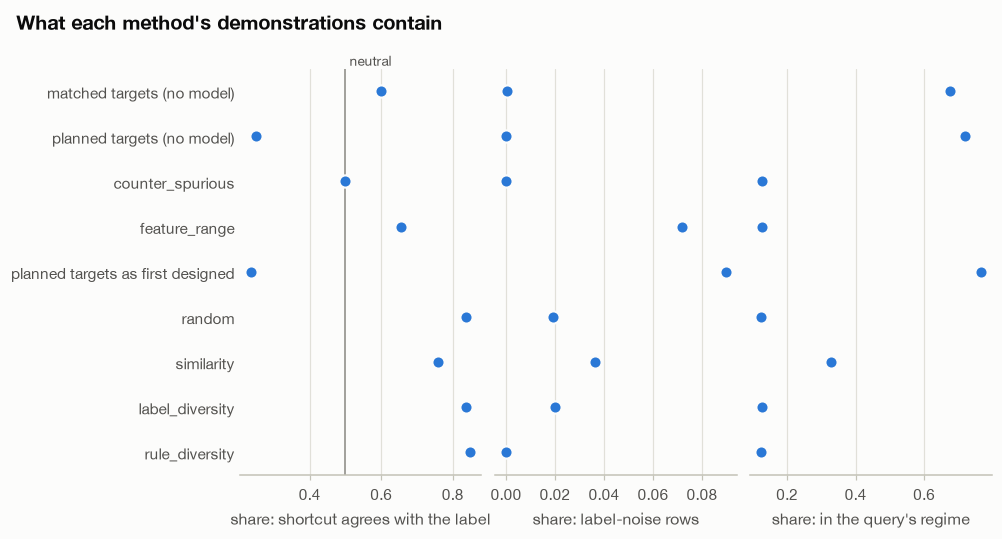

In [3]:
stats = table[["shortcut_agrees", "label_noise", "same_regime"]].rename(index=name).reset_index(names="method")
fig, axes = plots.panels(1, 3, title="What each method's demonstrations contain", size=(9.0, plots.dots_height(len(order)) + 0.8),
                         sharey=True)
for ax, col, xl, ref in zip(axes, ["shortcut_agrees", "label_noise", "same_regime"],
                            ["shortcut agrees with the label", "label-noise rows", "in the query's regime"],
                            [(0.5, "neutral"), None, None]):
    plots.dots(ax, stats, y="method", x=col, y_order=[name(m) for m in order], xlabel=f"share: {xl}")
    if ref:
        plots.reference(ax, *ref)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
plt.show()

**Reading the chart.**
- **Shortcut agreement is what separates the methods.** The strategies that show the shortcut working (0.76–0.85 agreement) fail under spurious reversal. counter_spurious and the matched targets sit near the neutral 0.5; the planned targets reverse it (0.25).
- **Label noise:** only feature_range (0.07) and the planned targets as first designed (0.09) pick many label-noise rows. The fix removed them from the planned targets.
- **Query's regime:** the targets put 68–77% of their rows in the query's regime, the strategies about 12.5% (one regime in eight), and similarity 33%.

## 2. Device: CPU or Apple Metal?

SATA's batches are small: 32 queries, each with 257 tokens. The plan asked for one timing of a full training step (forward, backward and Adam) on each device before training (`scripts/p5_train_sata.py --benchmark`).

In [4]:
bench = json.loads((P5 / "device_benchmark.json").read_text())
display(pd.Series({d: f"{s * 1000:.0f} ms" for d, s in bench["seconds_per_step"].items()}, name="per training step").to_frame())
print("faster:", bench["faster"])

,per training step
cpu,413 ms
mps,35 ms


faster: mps


## 3. Training

`scripts/p5_train_sata.py` trains each of the three models on 1,000 tasks for up to 50 epochs, with fresh data and a fresh feature order in every batch, from a seeded stream (seed 0).

**Two ways of turning SATA's scores into 8 demonstrations** are checked after every epoch (`hiccups/21`):
- **drawn**: 4 rows per label drawn in proportion to the scores, SATA's rule from P5;
- **top 4**: the 4 highest-scoring rows per label, the plan's original rule.

The best epoch under each rule is kept, and training stops once neither has improved for 10 epochs.

**Where it ran.** Epochs 0–15 (`sata`) or 0–16 (the other two) ran on the Mac's GPU (Apple Metal). The rest ran on a Runpod H200, resumed from the saved state. Each epoch's data comes from the same seeded stream, so the H200 continued the same training; only floating-point details differ.

,SATA-v2,"SATA-v2, blank query","SATA, planned targets"
epochs run,50,37,50
best epoch (drawn),39,26,49
best worst-environment proxy (drawn),0.652,0.56,0.635
best epoch (top 4),3,1,48
best worst-environment proxy (top 4),0.542,0.431,0.519
minutes,133.4,83.0,124.3
device,cuda,cuda,cuda


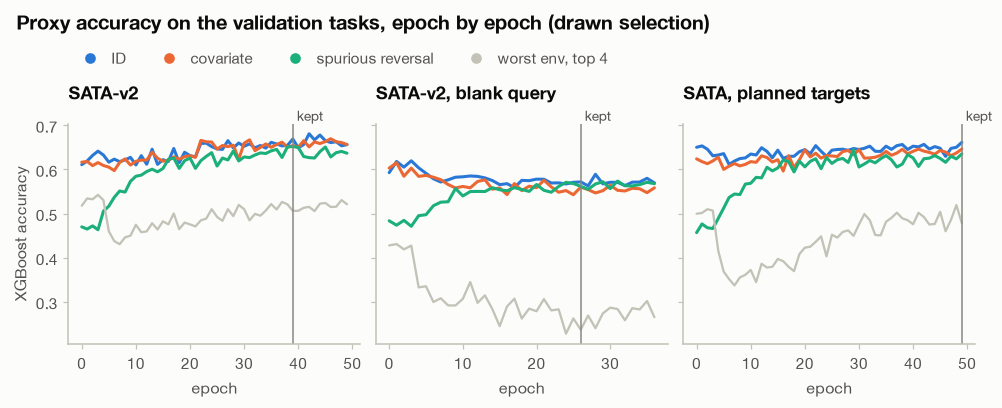

In [5]:
logs = {v: json.loads((P5 / f"train_{v}.json").read_text()) for v in VARIANTS}
display(pd.DataFrame({name(v): {"epochs run": len(l["log"]), "best epoch (drawn)": l["best_epoch"],
                                "best worst-environment proxy (drawn)": round(l["best_val_proxy"], 3),
                                "best epoch (top 4)": l["best_by_selection"]["topk"]["epoch"],
                                "best worst-environment proxy (top 4)": round(l["best_by_selection"]["topk"]["val_proxy"], 3),
                                "minutes": round(l["minutes"], 1), "device": l["device"]} for v, l in logs.items()}))
fig, axes = plots.panels(1, 3, title="Proxy accuracy on the validation tasks, epoch by epoch (drawn selection)", size=(9.0, 3.6), sharey=True)
for ax, (v, l) in zip(axes, logs.items()):
    df = pd.DataFrame(l["log"])
    for env, colour in ENV_COLOURS.items():
        ax.plot(df["epoch"], df[f"val_sample_{env}"], color=colour, linewidth=2)
    ax.plot(df["epoch"], df["val_proxy_topk"], color=plots.CONTEXT, linewidth=1.5)
    ax.axvline(l["best_epoch"], color=plots.MUTED, linewidth=1)
    ax.text(l["best_epoch"], 1.0, " kept", transform=ax.get_xaxis_transform(), color=plots.INK_2, fontsize=9, va="bottom")
    ax.set_title(name(v))
    ax.set_xlabel("epoch")
axes[0].set_ylabel("XGBoost accuracy")
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
plots.key(fig, [plots.label(e) for e in EVAL_ENVS] + ["worst env, top 4"], [*plots.SERIES, plots.CONTEXT])
plt.show()

**Reading the chart.**
- **SATA-v2 kept improving to epoch 39** (worst environment 0.652). Training stopped at epoch 49, after 10 epochs without improvement under either selection rule.
- **The grey line, the worst environment under top-4 selection,** stays near or below 0.5 for all three models. Taking the top-scored rows reverses the shortcut again, which is why SATA draws its demonstrations instead (`hiccups/21`).
- **The blank-query model** peaks at 0.560 (epoch 26). Without the query it cannot prefer the query's regime, so per-query conditioning is worth about 0.09 on the proxy.
- Epochs 0–15/16 ran on the Mac's GPU and the rest on the H200.

## 4. The trained models on the proxy

The same 100 validation tasks, pools, queries and feature orders as the gate, so each trained model sits directly against the targets it learned from and the strategies.

,id,covariate,spurious_reversal,mechanism,worst,shortcut_agrees,label_noise,same_regime
method,,,,,,,,
SATA-v2,0.669,0.654,0.652,0.640,0.652,0.515,0.030,0.480
matched targets (no model),0.655,0.671,0.640,0.681,0.640,0.598,0.000,0.676
"SATA, planned targets",0.662,0.646,0.635,0.629,0.635,0.499,0.031,0.399
"SATA-v2, blank query",0.572,0.560,0.562,0.599,0.560,0.542,0.038,0.127
planned targets (no model),0.556,0.585,0.671,0.589,0.556,0.251,0.000,0.720
counter_spurious,0.581,0.555,0.595,0.609,0.555,0.500,0.000,0.126
feature_range,0.578,0.575,0.507,0.596,0.507,0.657,0.072,0.125
SATA-v2 (top 4),0.506,0.532,0.676,0.522,0.506,0.244,0.037,0.602
"SATA, planned targets (top 4)",0.478,0.513,0.714,0.498,0.478,0.171,0.037,0.593


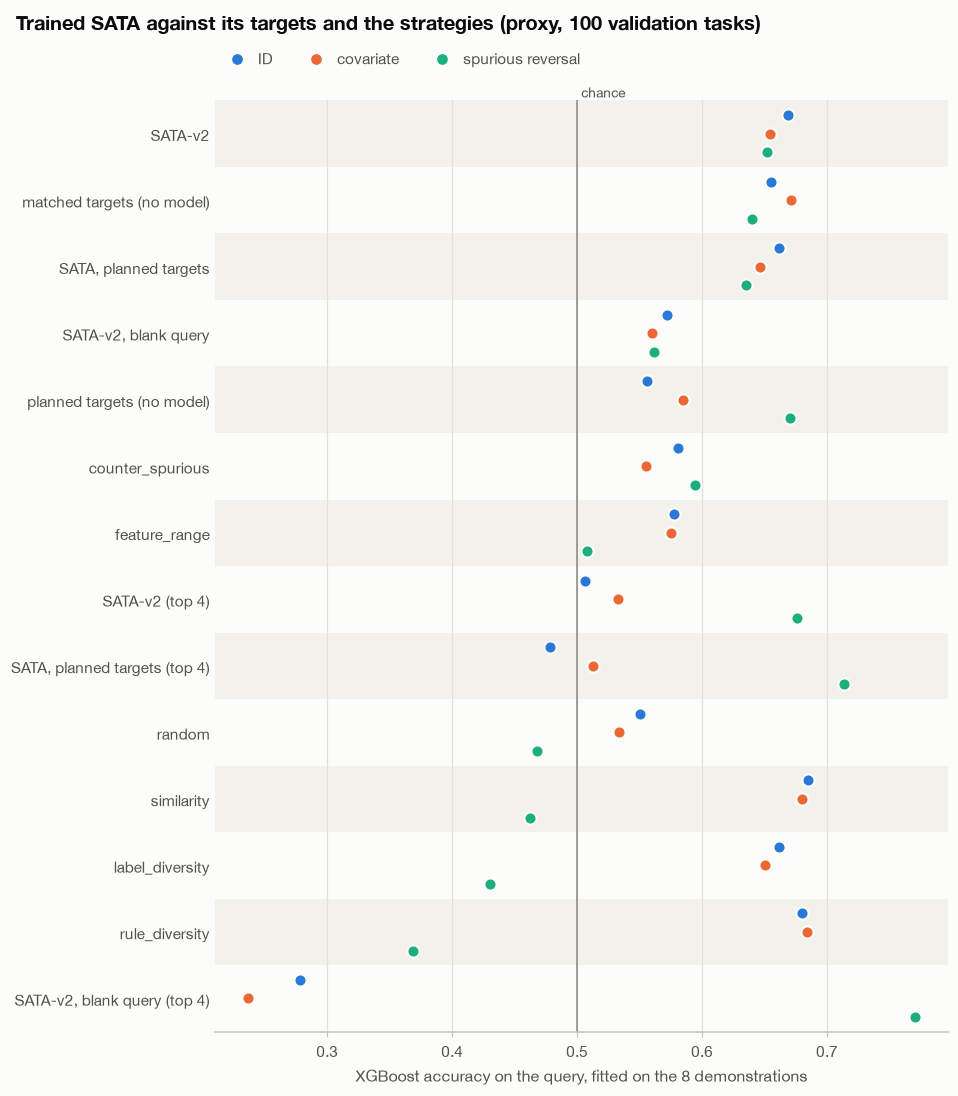

In [6]:
path = P5 / "proxy_trained.parquet"
if not path.exists():
    models = {v: load_sata(resolve_path(getattr(config.sata.checkpoints, v)), v, config.sata) for v in logs}
    _, val_tasks = sample_sata_tasks(0, config.generator.n_val_tasks, base_seed=config.generator.task_seed,
                                     spurious_strength_range=tuple(config.generator.spurious_strength_range),
                                     label_noise=config.generator.label_noise)
    trained = proxy_compare(val_tasks, cfg, methods=(), models=models, base_seed=config.selection.base_seed)
    trained.to_parquet(path, index=False)
trained = pd.read_parquet(path)
both = pd.concat([per_task[per_task.method != "oracle_target_designed"], trained], ignore_index=True)
table2 = summarise(both, EVAL_ENVS)
display(table2[[*EVAL_ENVS, "mechanism", "worst", "shortcut_agrees", "label_noise", "same_regime"]].rename(index=name).round(3))

order2 = list(table2.index)
long2 = both[both.env.isin(EVAL_ENVS)].groupby(["method", "env"])["accuracy"].mean().reset_index()
long2["method"] = long2["method"].map(name)
fig, (ax,) = plots.panels(title="Trained SATA against its targets and the strategies (proxy, 100 validation tasks)",
                          size=(8.6, plots.dots_height(len(order2), 3) + 0.7))
plots.dots(ax, long2, y="method", x="accuracy", hue="env", y_order=[name(m) for m in order2], hue_order=list(EVAL_ENVS),
           colours=plots.SERIES, xlabel="XGBoost accuracy on the query, fitted on the 8 demonstrations")
plots.reference(ax, 0.5, "chance")
plots.key(fig, [plots.label(e) for e in EVAL_ENVS], plots.SERIES)
plt.show()

**Reading the chart.**
- **Trained SATA-v2 (drawn) is the best method:** worst environment 0.652, with no weak environment (ID 0.669, covariate 0.654, reversal 0.652). Its sets show the shortcut agreeing in 52% of rows, near neutral.
- **SATA trained on the planned targets reaches 0.635 once its rows are drawn too.** Drawing alone removes most of the planned targets' reversal (agreement 0.50).
- **Under top-4 selection** every SATA model reverses the shortcut (agreement 0.01–0.24) and fails on ID. That confirms the switch to drawing.
- **The proxy is not Qwen.** Whether these demonstrations help the language model is section 5 here, and the confirmatory test is notebook 05, section 11.

## 5. LLM validation on 8 held-out tasks (stage F, run 11 October)

Stage F of `scripts/run_p4_pod.sh` runs on one H200. First Qwen's pool priors for the `sata_llmval` suite (for counter_prior). Then every strategy on those 8 tasks under all three namings. Then the evaluation grid's `sata`, `sata_agnostic` and `sata_designed` units. The RQ4 contrasts (R1–R6, frozen in `docs/research_plan.md`) are analysed in notebook 05.

```bash
bash scripts/run_p4_pod.sh F
```

naming            abstract                            aligned         \
env              covariate     id spurious_reversal covariate     id   
strategy                                                               
zero_shot            0.531  0.506             0.548     0.628  0.599   
random               0.510  0.633             0.458     0.596  0.716   
label_diversity      0.510  0.657             0.475     0.590  0.720   
feature_range        0.535  0.633             0.510     0.577  0.695   
rule_diversity       0.542  0.630             0.434     0.605  0.723   
counter_spurious     0.450  0.525             0.565     0.553  0.632   
similarity           0.611  0.651             0.466     0.575  0.700   
counter_prior        0.533  0.628             0.455     0.582  0.705   
sata                 0.535  0.582             0.531     0.563  0.627   
sata_agnostic        0.507  0.564             0.541     0.566  0.649   
sata_designed        0.492  0.609             0.536     0.583  0.641   

naming                               flipped                           
env              spurious_reversal covariate     id spurious_reversal  
strategy                                                               
zero_shot                    0.619     0.376  0.479             0.429  
random                       0.550     0.490  0.532             0.454  
label_diversity              0.590     0.455  0.537             0.468  
feature_range                0.567     0.435  0.491             0.460  
rule_diversity               0.543     0.438  0.510             0.447  
counter_spurious             0.674     0.387  0.425             0.492  
similarity                   0.569     0.558  0.552             0.464  
counter_prior                0.573     0.498  0.566             0.438  
sata                         0.627     0.486  0.487             0.507  
sata_agnostic                0.648     0.397  0.412             0.510  
sata_designed                0.606     0.490  0.506             0.511

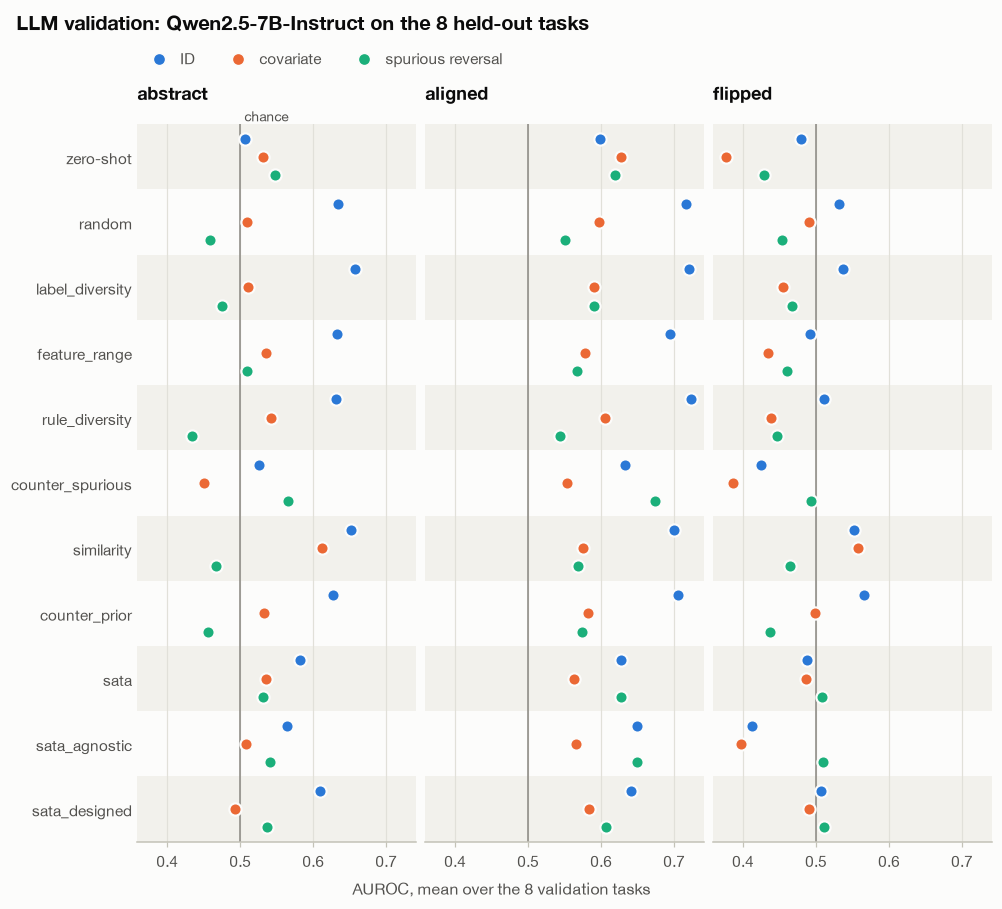

In [7]:
from src.evaluation.analysis import cell_metrics, summary_table

LLMVAL = RESULTS / "h200" / "p5" / "llmval.parquet"
cells = cell_metrics(pd.read_parquet(LLMVAL))
order = [s for s in plots.STRATEGIES if s in set(cells.strategy)]
display(summary_table(cells, value="auroc").reindex(order).round(3))
lv = (cells[cells.label_mode == "gold"].groupby(["naming", "strategy", "env", "task_id"])["auroc"].mean()
      .groupby(["naming", "strategy", "env"]).mean().reset_index())
fig = plots.facet_dots(lv, facet="naming", y="strategy", x="auroc", hue="env", facet_order=plots.NAMINGS,
                       hue_order=plots.ENVS, y_order=order, ref=0.5, ref_label="chance",
                       xlabel="AUROC, mean over the 8 validation tasks",
                       title="LLM validation: Qwen2.5-7B-Instruct on the 8 held-out tasks")
plt.show()

**Reading the chart.**
- **On Qwen2.5-7B-Instruct the proxy's advantage mostly disappears.** Under abstract names SATA has the best worst environment on these 8 tasks (0.531) but a lower ID AUROC than label_diversity (0.582 against 0.657).
- **Under aligned names** nothing beats zero-shot's worst environment (0.599). **Under flipped names** SATA and sata_designed are highest, but everything is near chance (≤ 0.49).
- **The proxy still ranks strategies roughly as Qwen does** (Spearman across strategy × environment: 0.68 abstract, 0.46 aligned, 0.46 flipped). Its gaps are much larger, because XGBoost can learn the rule from 8 rows and Qwen mostly cannot.


## 6. 5b: SATA-MI, which reads Qwen's measured prior (stage G, run 11 October)

**The idea.** SATA chose good demonstrations for a learner that reads the rule, but Qwen-Instruct mostly reads its "bigger → 1" prior (section 5, notebook 03.1). So 5b gives SATA what the prior looks like: for every pool row and the query, Qwen's measured zero-shot margin under the task's naming.
- `sata_mi`: input [x, m₀], width 11.
- `sata_names`, the control: input [x, s⊙x], where s is the displayed name's lexicon direction (±1, 0 for abstract names). No LLM measurement.
- Both learn the same targets on 300 fixed training tasks (`sata_mi_train`, Qwen priors measured for all 3 namings) and stop early on 60 (`sata_mi_val`).

**The proxy.** XGBoost cannot see names, so 5b scores sets with a small *reader* of how Qwen combines evidence and prior: score = a₁·(w·x) + a₂·m₀, with w a ridge logistic fitted on the 8 demonstrations and a₁, a₂ fitted on stage F's Qwen scores (`src/models/prior_proxy.py`). A set's proxy is the reader's AUROC within each (set, environment) cell.

```bash
bash scripts/run_5b_pod.sh    # EPOCHS=30 (the user's cap, for budget)
```


Gate S3a-MI: lambda 0.0, targets 0.619 against counter_spurious 0.586 -> PASS


,covariate,id,spurious_reversal,worst,abstract,aligned,flipped
method,,,,,,,
counter_prior,0.690,0.696,0.472,0.472,0.640,0.686,0.532
counter_spurious,0.586,0.606,0.613,0.586,0.620,0.668,0.516
label_diversity,0.685,0.682,0.475,0.475,0.633,0.680,0.529
"MI targets, λ = 0",0.699,0.646,0.619,0.619,0.674,0.728,0.562
"MI targets, λ = 0.5",0.704,0.652,0.616,0.616,0.678,0.729,0.564
"MI targets, λ = 1",0.703,0.652,0.617,0.617,0.678,0.729,0.564
random,0.663,0.661,0.482,0.482,0.619,0.660,0.528


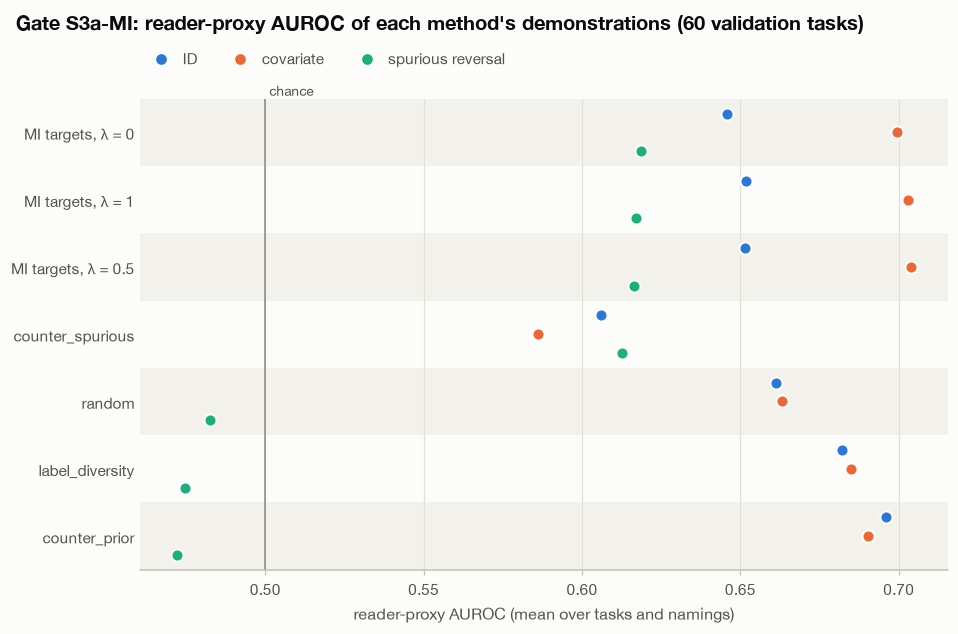

In [8]:

gmi = json.loads((P5 / "gate_s3a_mi.json").read_text())
gt = pd.DataFrame(gmi["table"]).set_index("method")
gt = gt.rename(index={"oracle_mi_0.0": "MI targets, λ = 0", "oracle_mi_0.5": "MI targets, λ = 0.5", "oracle_mi_1.0": "MI targets, λ = 1"})
print(f"Gate S3a-MI: lambda {gmi['lambda']}, targets {gmi['oracle_worst']:.3f} against {gmi['best_strategy']} "
      f"{gmi['best_strategy_worst']:.3f} -> {'PASS' if gmi['passed'] else 'FAIL'}")
display(gt.round(3))
long = gt[list(EVAL_ENVS)].reset_index().melt(id_vars="method", var_name="env", value_name="auroc")
order = list(gt.sort_values("worst", ascending=False).index)
fig, (ax,) = plots.panels(title="Gate S3a-MI: reader-proxy AUROC of each method's demonstrations (60 validation tasks)",
                          size=(8.6, plots.dots_height(len(order), 3) + 0.7))
plots.dots(ax, long, y="method", x="auroc", hue="env", y_order=order, hue_order=list(EVAL_ENVS), colours=plots.SERIES,
           xlabel="reader-proxy AUROC (mean over tasks and namings)")
plots.reference(ax, 0.5, "chance")
plots.key(fig, [plots.label(e) for e in EVAL_ENVS], plots.SERIES)
plt.show()



**Reading the chart.**
- **The gate passes:** the MI targets' worst environment is 0.619, against 0.586 for counter_spurious, the best hand-designed strategy.
- **The counter-prior bonus adds nothing:** λ = 0, 0.5 and 1 score 0.619, 0.616 and 0.617, so λ = 0 was kept. SATA-MI's targets are therefore the 5a matched targets; it differs from SATA only in reading the prior.
- **counter_prior, label_diversity and random collapse under spurious reversal** (0.47–0.48), as on Qwen in P4.


,sata_mi,sata_names
epochs run,30.000,30.000
best epoch (drawn),25.000,28.000
best worst-environment proxy (drawn),0.620,0.590
best worst-environment proxy (top 4),0.558,0.576
minutes,44.500,44.700


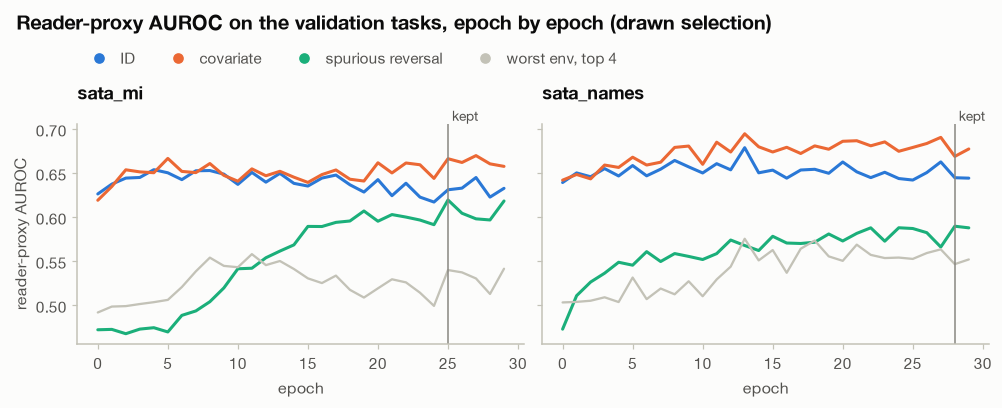

In [9]:

mi_logs = {v: json.loads((P5 / f"train_{v}.json").read_text()) for v in ("sata_mi", "sata_names")}
display(pd.DataFrame({v: {"epochs run": len(l["log"]), "best epoch (drawn)": l["best_epoch"],
                          "best worst-environment proxy (drawn)": round(l["best_val_proxy"], 3),
                          "best worst-environment proxy (top 4)": round(l["best_topk"], 3),
                          "minutes": round(l["minutes"], 1)} for v, l in mi_logs.items()}))
fig, axes = plots.panels(1, 2, title="Reader-proxy AUROC on the validation tasks, epoch by epoch (drawn selection)",
                         size=(9.0, 3.6), sharey=True)
for ax, (v, l) in zip(axes, mi_logs.items()):
    df = pd.DataFrame(l["log"])
    for env, colour in ENV_COLOURS.items():
        ax.plot(df["epoch"], df[f"val_sample_{env}"], color=colour, linewidth=2)
    ax.plot(df["epoch"], df["val_proxy_topk"], color=plots.CONTEXT, linewidth=1.5)
    ax.axvline(l["best_epoch"], color=plots.MUTED, linewidth=1)
    ax.text(l["best_epoch"], 1.0, " kept", transform=ax.get_xaxis_transform(), color=plots.INK_2, fontsize=9, va="bottom")
    ax.set_title(v)
    ax.set_xlabel("epoch")
axes[0].set_ylabel("reader-proxy AUROC")
axes[1].tick_params(labelleft=False)
plots.key(fig, [plots.label(e) for e in EVAL_ENVS] + ["worst env, top 4"], [*plots.SERIES, plots.CONTEXT])
plt.show()



**Reading the chart.**
- **SATA-MI reaches the targets' own level on the proxy:** worst environment 0.620 at epoch 25 (targets 0.619), against 0.590 for SATA-names (epoch 28).
- **The gain is all in spurious reversal** (0.620 against 0.590). On ID and covariate the two are level (0.631/0.666 against 0.645/0.669).
- **Training was capped at 30 epochs** for budget. SATA-MI's spurious-reversal line is still edging up at the cap (0.620 at epochs 25 and 29), so longer training might add a little on the proxy. It already matches its targets, so the room left is small.
- **Top-4 selection again lags drawn selection** (grey), as in 5a.


naming           abstract                            aligned         \
env             covariate     id spurious_reversal covariate     id   
strategy                                                              
sata_mi             0.502  0.585             0.564     0.558  0.634   
sata_names          0.539  0.549             0.501     0.610  0.646   
sata                0.535  0.582             0.531     0.563  0.627   
counter_prior       0.533  0.628             0.455     0.582  0.705   
label_diversity     0.510  0.657             0.475     0.590  0.720   
random              0.510  0.633             0.458     0.596  0.716   

naming                              flipped                           
env             spurious_reversal covariate     id spurious_reversal  
strategy                                                              
sata_mi                     0.628     0.478  0.509             0.525  
sata_names                  0.655     0.514  0.510             0.554  
sata                        0.627     0.486  0.487             0.507  
counter_prior               0.573     0.498  0.566             0.438  
label_diversity             0.590     0.455  0.537             0.468  
random                      0.550     0.490  0.532             0.454

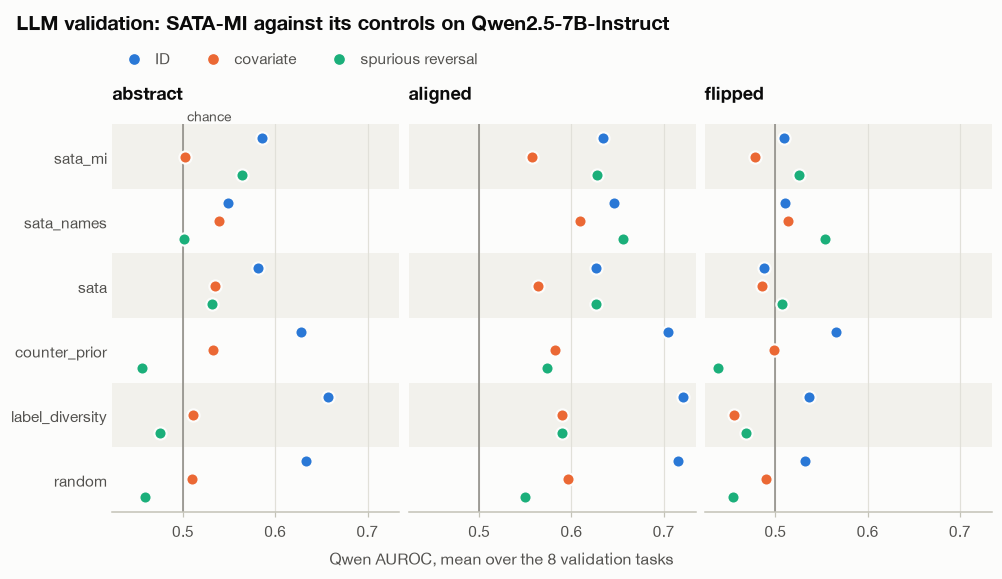

In [10]:

from src.evaluation.analysis import cell_metrics, summary_table
HP5 = RESULTS / "h200" / "p5"
lvm = pd.concat([pd.read_parquet(HP5 / "llmval.parquet"), pd.read_parquet(HP5 / "llmval_mi.parquet")], ignore_index=True)
cm = cell_metrics(lvm)
show = ["sata_mi", "sata_names", "sata", "counter_prior", "label_diversity", "random"]
lv = (cm[(cm.label_mode == "gold") & cm.strategy.isin(show)].groupby(["naming", "strategy", "env", "task_id"])["auroc"].mean()
      .groupby(["naming", "strategy", "env"]).mean().reset_index())
display(lv.pivot_table(index="strategy", columns=["naming", "env"], values="auroc").reindex(show).round(3))
fig = plots.facet_dots(lv, facet="naming", y="strategy", x="auroc", hue="env", facet_order=plots.NAMINGS,
                       hue_order=plots.ENVS, y_order=show, ref=0.5, ref_label="chance",
                       xlabel="Qwen AUROC, mean over the 8 validation tasks",
                       title="LLM validation: SATA-MI against its controls on Qwen2.5-7B-Instruct")
plt.show()



**Reading the chart.**
- **Gate 5b's second half fails.** SATA-MI should beat both controls on the LLM validation. It does under abstract names (mean 0.551 against 0.530 for SATA-names and 0.539 for counter_prior). Under aligned names it is below both (0.607 against 0.637 and 0.620). Under flipped names it beats counter_prior (0.504 against 0.501) but not SATA-names (0.526).
- **Under flipped names every strategy sits near chance** (0.49–0.53 on average), which is where SATA-MI was meant to help.
- **SATA-MI looks like SATA:** within 0.01 of it under every naming.


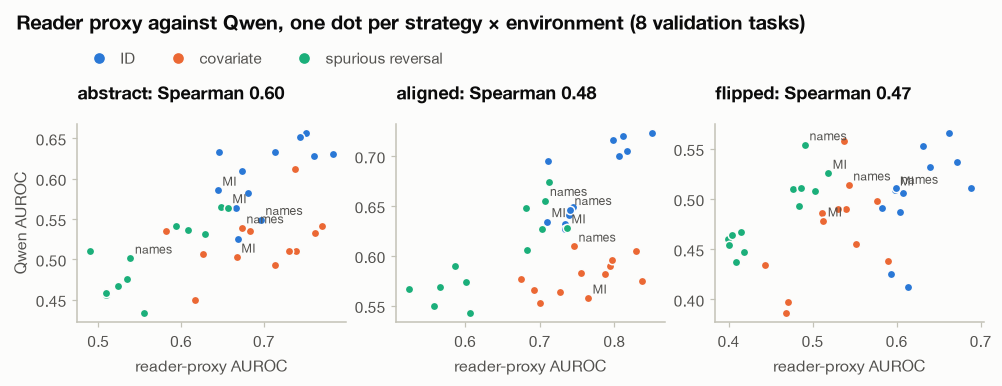

In [11]:

pq = pd.read_parquet(P5 / "llmval_mi_proxy_vs_qwen.parquet")
g5b = json.loads((P5 / "gate_5b.json").read_text())
fig, axes = plots.panels(1, 3, title="Reader proxy against Qwen, one dot per strategy × environment (8 validation tasks)",
                         size=(9.0, 3.4), sharey=False)
for ax, n in zip(axes, plots.NAMINGS):
    d = pq[pq.naming == n]
    for env, colour in zip(plots.ENVS, plots.SERIES):
        e = d[d.env == env]
        ax.scatter(e["proxy"], e["auroc"], s=30, color=colour, edgecolor=plots.SURFACE, linewidth=1, zorder=3)
    for s in ("sata_mi", "sata_names"):
        for _, r in d[d.strategy == s].iterrows():
            ax.annotate("MI" if s == "sata_mi" else "names", (r["proxy"], r["auroc"]), fontsize=8, color=plots.INK_2,
                        xytext=(3, 3), textcoords="offset points")
    ax.set_title(f"{plots.label(n)}: Spearman {g5b['spearman'][n]:.2f}")
    ax.set_xlabel("reader-proxy AUROC")
axes[0].set_ylabel("Qwen AUROC")
plots.key(fig, [plots.label(e) for e in plots.ENVS], plots.SERIES)
plt.show()



**Reading the chart.**
- **Gate 5b's first half fails for named tasks.** Proxy–Qwen Spearman is 0.60 under abstract names but 0.48 (aligned) and 0.47 (flipped), below the 0.5 bar. Pooled over namings it is 0.76, but most of that is the naming itself (aligned tasks score higher on both).
- **The reader was fitted on these same 8 tasks,** so these correlations are if anything optimistic.
- **The reader proxy is no better than XGBoost's was in 5a** (0.68 / 0.46 / 0.46). Adding Qwen's prior to the proxy did not make it track Qwen's ranking of strategies within a naming.
